# 02 · The burst catalogue

The data file `data/srb_notST4_2010_df.txt` is a catalogue of solar radio
bursts. Each row is one burst:

| column      | meaning                                         |
|-------------|-------------------------------------------------|
| `datetime`  | time of the burst                               |
| `station`   | observing station                               |
| `peak_flux` | peak flux in solar flux units (SFU)             |
| `st`        | spectral type as given in the source catalogue  |

This notebook loads it and shows the whole record as a time series.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt

from srb.config import FIGURES_DIR
from srb.data import load_catalogue
from srb.plotting import plot_peak_flux_timeline

## Parameters

In [2]:
START_DATE = "1966-01-16"
END_DATE = "2026-05-10"

## Load the catalogue

In [3]:
df = load_catalogue()
df.head()

,datetime,station,peak_flux,st
0,1966-01-16 01:07:30,SGMR,14.0,NaN
1,1966-01-16 01:09:54,SGMR,28.0,NaN
2,1966-01-17 01:08:06,SGMR,24.0,NaN
3,1966-01-17 01:21:18,SGMR,58.0,NaN
4,1966-01-18 01:30:00,SGMR,7.0,NaN


In [4]:
in_period = df[(df["datetime"] >= START_DATE) & (df["datetime"] <= END_DATE + " 23:59:59")]
print(f"Number of events between {START_DATE} and {END_DATE}: {len(in_period)}")

Number of events between 1966-01-16 and 2026-05-10: 14475


## Peak flux over time

Each vertical line is one burst. Its height is the peak flux on a logarithmic axis. Only a handful exceed 10⁵–10⁶ SFU. Those rare extremes are what the forecasting notebook targets.

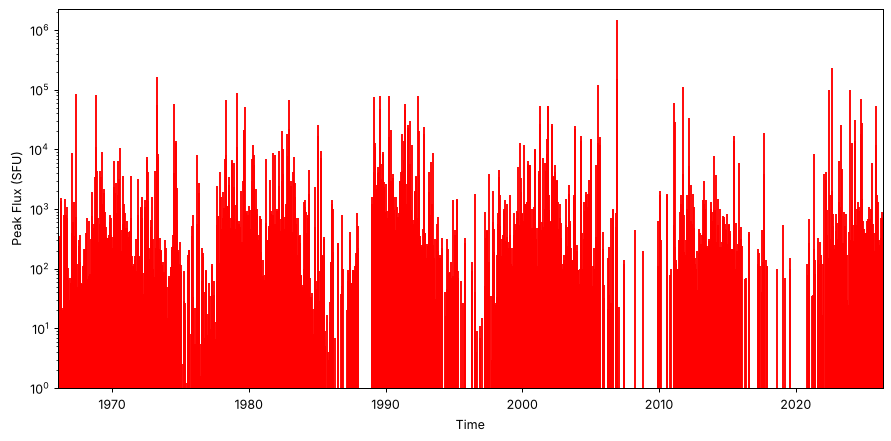

In [5]:
fig = plot_peak_flux_timeline(in_period, START_DATE, END_DATE)
fig.savefig(FIGURES_DIR / "peak_flux_timeline.png", dpi=200)
plt.show()